In [11]:
import pandas as pd
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import matplotlib.pyplot as plt
import seaborn as sns

In [12]:
df = pd.read_excel('Online Retail.xlsx')
display(df.head())
print('Shape:', df.shape)
df.info()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Shape: (541909, 8)
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 40.0+ MB


In [13]:
print('Baris awal:', len(df), '| Invoice awal:', df['InvoiceNo'].nunique())
df = df.dropna(subset=['Description'])
df['InvoiceNo'] = df['InvoiceNo'].astype(str)
df = df[~df['InvoiceNo'].str.startswith('C')]
df = df[df['Quantity'] > 0]
df['Description'] = df['Description'].str.strip()
print('Baris bersih:', len(df), '| Invoice bersih:', df['InvoiceNo'].nunique())

Baris awal: 541909 | Invoice awal: 25900
Baris bersih: 530693 | Invoice bersih: 20136


In [14]:
basket = df.groupby(['InvoiceNo', 'Description'])['Quantity'].sum().unstack(fill_value=0) > 0
display(basket.head())

Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD,12 HANGING EGGS HAND PAINTED,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,...,returned,taig adjust,test,to push order througha s stock was,website fixed,wrongly coded 20713,wrongly coded 23343,wrongly marked,wrongly marked 23343,wrongly sold (22719) barcode
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536365,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536366,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536367,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536368,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536369,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [15]:
frequent_itemsets = fpgrowth(basket, min_support=0.02, use_colnames=True)
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.5)
print('Jumlah Frequent Itemsets:', len(frequent_itemsets))
print('Jumlah Rules:', len(rules))

Jumlah Frequent Itemsets: 376
Jumlah Rules: 61


In [16]:
rules = rules.sort_values('lift', ascending=False)
display(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(10))

,antecedents,consequents,support,confidence,lift
53,frozenset({PINK REGENCY TEACUP AND SAUCER}),"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",0.026917,0.707572,18.551648
50,"frozenset({GREEN REGENCY TEACUP AND SAUCER, RO...",frozenset({PINK REGENCY TEACUP AND SAUCER}),0.026917,0.705729,18.551648
51,"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.026917,0.904841,17.950627
52,frozenset({GREEN REGENCY TEACUP AND SAUCER}),"frozenset({PINK REGENCY TEACUP AND SAUCER, ROS...",0.026917,0.533990,17.950627
45,frozenset({GREEN REGENCY TEACUP AND SAUCER}),frozenset({PINK REGENCY TEACUP AND SAUCER}),0.031436,0.623645,16.393893
46,frozenset({PINK REGENCY TEACUP AND SAUCER}),frozenset({GREEN REGENCY TEACUP AND SAUCER}),0.031436,0.826371,16.393893
49,"frozenset({GREEN REGENCY TEACUP AND SAUCER, PI...",frozenset({ROSES REGENCY TEACUP AND SAUCER}),0.026917,0.856240,16.173782
54,frozenset({ROSES REGENCY TEACUP AND SAUCER}),"frozenset({GREEN REGENCY TEACUP AND SAUCER, PI...",0.026917,0.508443,16.173782
59,frozenset({GARDENERS KNEELING PAD KEEP CALM}),frozenset({GARDENERS KNEELING PAD CUP OF TEA}),0.027116,0.598028,15.886413
60,frozenset({GARDENERS KNEELING PAD CUP OF TEA}),frozenset({GARDENERS KNEELING PAD KEEP CALM}),0.027116,0.720317,15.886413


3 ATURAN TERBAIK BERDASARKAN LIFT
Rule: {'PINK REGENCY TEACUP AND SAUCER'} -> {'GREEN REGENCY TEACUP AND SAUCER', 'ROSES REGENCY TEACUP AND SAUCER'} | Support: 0.0269 | Confidence: 0.7076 | Lift: 18.5516
Rule: {'GREEN REGENCY TEACUP AND SAUCER', 'ROSES REGENCY TEACUP AND SAUCER'} -> {'PINK REGENCY TEACUP AND SAUCER'} | Support: 0.0269 | Confidence: 0.7057 | Lift: 18.5516
Rule: {'PINK REGENCY TEACUP AND SAUCER', 'ROSES REGENCY TEACUP AND SAUCER'} -> {'GREEN REGENCY TEACUP AND SAUCER'} | Support: 0.0269 | Confidence: 0.9048 | Lift: 17.9506


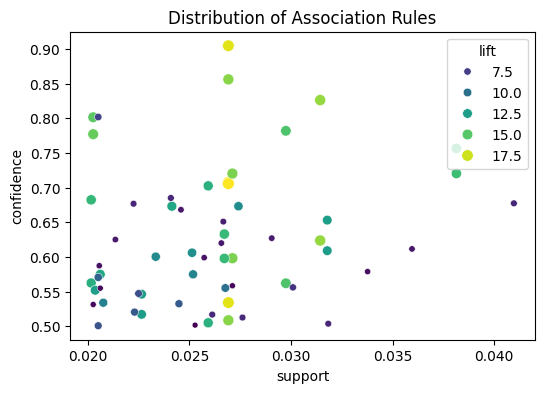

In [17]:
top3 = rules.head(3)
print('3 ATURAN TERBAIK BERDASARKAN LIFT')
for idx, row in top3.iterrows():
    print(f"Rule: {set(row['antecedents'])} -> {set(row['consequents'])} | Support: {row['support']:.4f} | Confidence: {row['confidence']:.4f} | Lift: {row['lift']:.4f}")

plt.figure(figsize=(6, 4))
sns.scatterplot(x='support', y='confidence', size='lift', data=rules, hue='lift', palette='viridis')
plt.title('Distribution of Association Rules')
plt.show()